# Measure mining-front coherence and minimum width

**Question:** How does a feasible CPIT schedule fragment a bench, and what changes when narrow runs are smoothed?

**Level:** 1 — Fundamentals

**Prerequisites:** Complete topic 01, CPIT scheduling and bounds.

**Reading time:** 18 minutes

## Objectives

A block-level schedule can satisfy precedence and capacity while scattering extraction across disconnected fronts. This lesson measures that operational shape instead of treating NPV as the only result. Build a synthetic 3D case, solve it, compute six-neighbour components and bench run widths, then call OreBlocks' width smoother. The smoother may move a narrow run toward the period chosen by its bench neighbours, but it only accepts moves that preserve precedence and leave room in every receiving resource. It is a post-process, not a width-constrained optimizer. The teaching geometry is small and width is measured in blocks, not metres. The resulting plan is not a mine design or a geotechnical approval.

## Setup

Install the pinned environment from the repository root with `python -m pip install -r notebooks/requirements.txt`. `oreblocks==0.6.3`.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Load the PhaseFlow instance pipeline and OreBlocks geometry methods.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.3


## Data

The declared input is generated by PhaseFlow's MIT-licensed pipeline: synthetic porphyry twin, dimensions 8×8×4, fixed seed 41, six periods and two resource limits. The pipeline supplies block coordinates, precedence, grade and tonnage. OreBlocks 0.6.3 computes the schedule, coherence metrics and width smoothing. No published MineLib block model is used. The width target is in grid blocks because this case has no surveyed block dimension; never convert it to metres without a declared grid size. The Bai et al. source discusses approximately 100 m as a mining-width target in a different pushback-design model. That value is context, not the target of this synthetic schedule.

## Method

For period t, coherence counts six-neighbour connected components among blocks assigned to t. Bench width is the minimum consecutive mined run along either horizontal grid axis. These are indicators of fragmentation, not complete operating constraints. `enforce_min_width` considers mined blocks whose run is narrower than a target, votes among four same-bench neighbours for a receiving period, and accepts the move only if precedence holds in both directions and all receiving resource limits remain feasible. It repeats a bounded number of passes. The output report includes before/after narrow-block counts, moved blocks, capacity refusals, NPV and minimum width. The schedule must be feasible before the call. A feasible result still needs operational review; these geometric indicators do not model haul roads, equipment, slope or access.

### Step 1: build the case

The pipeline builds a 256-block teaching instance and validates its contract. Coordinates identify adjacency, while the precedence graph constrains extraction order. Read the two resource limits as part of the case: a width move that fits mining but overfills processing must be refused. The code reports dimensions and accepted status so later measurements have a known input.

In [2]:
# Generate one seeded synthetic case through the PhaseFlow pipeline.
case = Case(
    id='operability-porphyry-8x8x4', category='teaching',
    title_en='Porphyry coherence lesson', title_es='Leccion de coherencia porfídica',
    deposit=DepositSpec(kind='twin', archetype='porphyry', dims=(8, 8, 4), seed=41),
    scenario=Scenario(periods=6, discount_rate=0.08,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 256


### Step 2: solve the feasible schedule

The Expected heuristic constructs a schedule under the declared CPIT constraints. Keep its period assignment and NPV as the baseline. A feasible high-value plan can still split a bench into multiple disconnected components; value and geometric coherence answer different questions. We measure the unsmoothed schedule before changing it, so the comparison does not rely on a stored artifact or a chart copied from the product bake.

In [3]:
# Solve a deterministic CPIT plan and retain its period assignments.
schedule, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
print(schedule.method, '| NPV:', round(schedule.npv, 2), '| mined:', schedule.mined_blocks)

toposort:expected[r1] | NPV: 6241283.54 | mined: 113


### Step 3: measure and smooth

`schedule_coherence` returns period-level components, largest component and minimum bench width. `enforce_min_width` then returns a new schedule plus a report. The before/after counts make the mechanism visible: some slivers move, while those with no receiving capacity remain. Because the method validates precedence and resource room during each move, its NPV difference reflects a feasible post-process under these constraints, not a capacity overrun. It does not insert new blocks or alter the ultimate pit.

In [4]:
# Measure the baseline plan's per-period coherence.
before = ob.schedule_coherence(
    schedule.period_of_block, instance.x, instance.y,
    instance.level, instance.cpit.n_periods,
)
print([(row.period, row.components, row.min_width_blocks) for row in before])

[(0, 1, 1), (1, 4, 1), (2, 5, 1), (3, 8, 1), (4, 6, 1), (5, 3, 1)]


Now call the package post-process with target width three. It returns both a new schedule and an audit report; measure coherence again on the returned assignments.

In [5]:
# Smooth narrow runs, then measure coherence on the returned schedule.
smoothed, report = ob.enforce_min_width(
    instance.cpit, schedule, instance.x, instance.y, instance.level,
    instance.precedence, target_width=3,
)
after = ob.schedule_coherence(
    smoothed.period_of_block, instance.x, instance.y,
    instance.level, instance.cpit.n_periods,
)
print('moved:', report.moved_blocks, '| capacity refusals:', report.blocked_by_capacity)
print('narrow blocks:', report.below_target_before, 'to', report.below_target_after)
print('NPV:', round(report.npv_before, 2), 'to', round(report.npv_after, 2))

moved: 25 | capacity refusals: 29
narrow blocks: 90 to 89
NPV: 6241283.54 to 6245690.97


Plot the package's before/after narrow-block counts. Read the count with the moved and refused totals; it is a grid indicator, not a physical width guarantee.

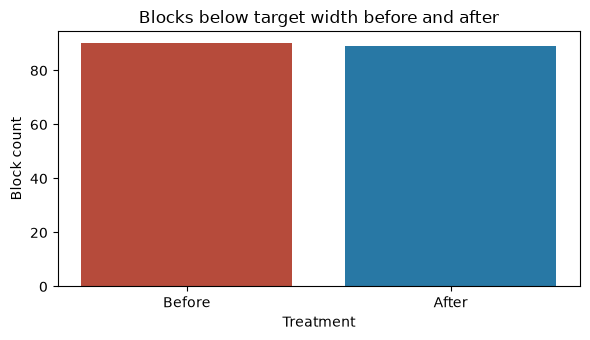

In [6]:
# Plot measured blocks below the target width before and after smoothing.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['Before', 'After'], [report.below_target_before, report.below_target_after], color=['#b64b3b', '#2878a5'])
ax.set(title='Blocks below target width before and after', xlabel='Treatment', ylabel='Block count')
fig.tight_layout()
plt.show()

### Figure 1

Plot the computed count of mined blocks in runs narrower than three blocks, before and after smoothing. A reduction indicates that eligible runs were absorbed; an unchanged count can result from isolated geometry or blocked moves. The chart does not show access, phase boundaries, equipment turning radius, or geotechnical risk. Its unit is a count of blocks in this declared grid. Compare the report's moved and capacity-blocked counts to understand why the width indicator changed by the amount shown.

The geometry report does not certify precedence or resource feasibility; this control call checks the returned schedule itself.

In [7]:
# Confirm the width post-process still satisfies scheduling invariants.
postprocess_controls = ob.run_controls(instance.cpit, instance.precedence, smoothed)
print('post-process controls pass:', postprocess_controls.all_pass)


post-process controls pass: True


## Results

**Answer:** The width-3 pass moved 25 blocks, with 29 moves refused by capacity, and reduced blocks below target width from 90 to 89. NPV rose from 6241283.54 to 6245690.97, a gain of 4407.43 value units; this synthetic result does not establish physical operability.

In [8]:
# Print computed answer quantities from the smoothing report.
print(f'moved={report.moved_blocks}; blocked={report.blocked_by_capacity}')
print(f'below_width={report.below_target_before}->{report.below_target_after}')
print(f'npv_change={report.npv_after-report.npv_before:.2f}')

moved=25; blocked=29
below_width=90->89
npv_change=4407.43


## Summary

You measured schedule shape before and after calling the package's bounded width smoother. It preserves modeled precedence and capacity, but only moves blocks that have a feasible receiving period. Interpret width in blocks and the geometric indicators as evidence for review, not as a complete operational model. A real design needs surveyed dimensions, access and haulage constraints, geotechnical review, and potentially width variables inside the optimization rather than a post-process.

## References

- OreBlocks 0.6.3: `oreblocks.schedule_coherence`, `oreblocks.enforce_min_width`.
- Chicoisne et al. (2012), multi-period open-pit planning: https://doi.org/10.1287/opre.1120.1050.
- Bai et al. (2018), minimum mining width and pushback design: https://doi.org/10.17159/2411-9717/2018/v118n5a8.
- PhaseFlow method evidence: `docs/methodologies/10_operability.md`.